# P07. Coletor de dados via API

Quero montar um coletor que busque dados públicos brasileiros, trate as falhas que aparecem no caminho e guarde um histórico que eu possa reaproveitar em outros projetos. Escolhi três fontes que cobrem o mesmo recorte, Juiz de Fora entre 2022 e 2026: a carga de energia do sistema elétrico (ONS), o clima de uma estação meteorológica (INMET) e o preço de gasolina e etanol nos postos (ANP). No fim, cruzo as três em dois gráficos.

Nenhuma delas entrega os dados do mesmo jeito. O ONS tem uma API de catálogo que aponta para arquivos CSV, o INMET tem uma API que não devolveu o que eu precisava e arquivos anuais compactados, e a ANP só tem uma página com links. Cada seção mostra o que encontrei e como o coletor lida com isso.

In [1]:
import calendar
import io
import time
import zipfile
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup

import estilo as e

pasta = Path("../data")
pasta.mkdir(exist_ok=True)

## ONS: carga de energia

O portal de dados abertos do ONS usa CKAN, uma plataforma de catálogos. Cada conjunto de dados é um pacote, e a API devolve a lista deles e, para cada um, os arquivos que o compõem. Começo pela lista.

In [2]:
api_ons = "https://dados.ons.org.br/api/3/action"
resp = requests.get(f"{api_ons}/package_list", timeout=30)
print(resp.status_code)

dados = resp.json()
print(dados.keys())
print(dados["success"], len(dados["result"]))
dados["result"][:10]

200
dict_keys(['help', 'success', 'result'])
True 85


['ambiente-colaborativo',
 'bacia_contorno',
 'balanco_dessem_detalhe',
 'balanco_dessem_geral',
 'balanco-energia-subsistema',
 'capacidade-geracao',
 'capacidade-transformacao',
 'carga-energia',
 'carga-energia-programada',
 'carga-energia-verificada']

O ONS publica 85 conjuntos. A resposta é um dicionário com três chaves (`help`, `success` e `result`), e os nomes dos conjuntos ficam em `result`. O que me interessa é `carga-energia`, a carga diária por subsistema.

In [3]:
resp = requests.get(f"{api_ons}/package_show", params={"id": "carga-energia"}, timeout=30)
print(resp.status_code, resp.url)

ficha = resp.json()["result"]
print(ficha["title"], ficha["num_resources"])

recursos = pd.DataFrame(ficha["resources"])[["name", "format", "size", "last_modified", "url"]]
recursos["format"].value_counts()

200 https://dados.ons.org.br/api/3/action/package_show?id=carga-energia
Carga de Energia Diária 83


format
CSV        27
XLSX       27
PARQUET    27
PDF         1
JSON        1
Name: count, dtype: int64

O conjunto tem 83 arquivos: um PDF e um JSON com o dicionário de dados e, para cada ano de 2000 a 2026, o mesmo dado em CSV, XLSX e Parquet. Fico com o CSV, que é texto simples e se lê em qualquer lugar.

In [4]:
so_csv = recursos[recursos["format"] == "CSV"].copy()
so_csv["ano"] = so_csv["name"].str.split("-").str[-1].astype(int)
so_csv = so_csv.sort_values("ano").reset_index(drop=True)
print(so_csv.shape)
so_csv[["name", "ano", "size", "last_modified"]].tail(3)

(27, 6)


,name,ano,size,last_modified
24,Carga_Energia-2024,2024,54654.0,2025-07-28T15:34:13.022869
25,Carga_Energia-2025,2025,54504.0,2026-01-31T22:01:25.205259
26,Carga_Energia-2026,2026,46206.0,2026-10-11T22:00:45.416269


São 27 arquivos, um por ano. O catálogo anuncia o tamanho de cada um, e é isso que vou usar para saber se um arquivo local ainda está atualizado. O de 2025 tem última modificação em 31/01/2026, logo depois do fim do ano. O de 2026 muda com frequência e é menor, porque o ano ainda está em andamento.

In [5]:
url_ruim = "https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/carga_energia_di/CARGA_ENERGIA_1900.csv"
r = requests.get(url_ruim, timeout=10)
print(r.status_code, len(r.content))
print(r.text[:120])

404 338
<?xml version="1.0" encoding="UTF-8"?>
<Error><Code>NoSuchKey</Code><Message>The specified key does not exist.</Message>


Pedi de propósito um ano que não existe. O servidor respondeu 404, mas o `requests` não reclamou, porque do ponto de vista dele o servidor respondeu. O corpo da resposta tem 318 bytes e é uma mensagem de erro em XML. Se eu gravasse isso num arquivo `.csv` sem olhar o status, o histórico ficaria contaminado sem aviso. Por isso toda chamada confere o status, e erros do tipo 4xx e 5xx recebem tratamentos diferentes.

In [6]:
def baixar(url, tentativas=3, espera=1):
    for n in range(1, tentativas + 1):
        try:
            r = requests.get(url, timeout=(10, 60))
            r.raise_for_status()
            return r.content
        except requests.exceptions.HTTPError as erro:
            if r.status_code < 500:
                raise
            print(f"tentativa {n}: erro do servidor ({r.status_code})")
        except requests.exceptions.RequestException as erro:
            print(f"tentativa {n}: {type(erro).__name__}")
        if n < tentativas:
            time.sleep(espera * 2 ** (n - 1))
    raise RuntimeError(f"falhou depois de {tentativas} tentativas: {url}")


try:
    baixar(url_ruim)
except requests.exceptions.HTTPError as erro:
    print("desistiu na hora:", erro)

desistiu na hora: 404 Client Error: Not Found for url: https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/carga_energia_di/CARGA_ENERGIA_1900.csv


A função `baixar` põe um tempo limite em toda requisição, levanta erro quando o status não é de sucesso e só tenta de novo quando vale a pena. Um 404 é um pedido errado, e repetir o mesmo pedido dá o mesmo erro, então ela desiste na hora. Erro 5xx, tempo esgotado e conexão derrubada tentam de novo, com espera crescente entre as tentativas.

In [7]:
def precisa_baixar(linha, pasta):
    arquivo = pasta / f"carga_energia_{linha['ano']}.csv"
    if not arquivo.exists():
        return True
    return arquivo.stat().st_size != linha["size"]


pendentes = [l["ano"] for _, l in so_csv.iterrows() if precisa_baixar(l, pasta)]
print(len(pendentes), pendentes)

falhas = []
for ano in pendentes:
    url_ano = so_csv.loc[so_csv["ano"] == ano, "url"].iloc[0]
    try:
        conteudo = baixar(url_ano)
    except (requests.exceptions.RequestException, RuntimeError) as erro:
        falhas.append(ano)
        print(f"{ano}: falhou ({erro})")
        continue
    (pasta / f"carga_energia_{ano}.csv").write_bytes(conteudo)
    print(ano, len(conteudo))
    time.sleep(0.5)

print("falhas:", falhas)

0 []
falhas: []


O coletor é incremental. Antes de baixar um ano, compara o tamanho do arquivo local com o que o catálogo anuncia e pula se os dois baterem. Na primeira execução ele baixa os 27 anos. Aqui, com os arquivos já em disco, a lista de pendentes veio vazia. Quando o ONS atualizar o arquivo de 2026, o tamanho local deixa de bater e só esse ano é baixado de novo. A comparação por tamanho é uma aproximação: uma correção que mantivesse o mesmo número de bytes passaria despercebida.

In [8]:
pendentes = [l["ano"] for _, l in so_csv.iterrows() if precisa_baixar(l, pasta)]
print(len(pendentes), pendentes)

0 []


Uma segunda checagem logo depois da coleta confirma que não sobrou nada pendente.

In [9]:
partes = []
for arquivo in sorted(pasta.glob("carga_energia_*.csv")):
    parte = pd.read_csv(arquivo, sep=";", parse_dates=["din_instante"])
    parte["arquivo"] = arquivo.stem
    partes.append(parte)

historico = pd.concat(partes, ignore_index=True)
print(historico.shape)
print(historico.dtypes)

resumo = historico.groupby("arquivo")["din_instante"].agg(["size", "nunique", "min", "max"])
resumo

(39117, 5)
id_subsistema                       str
nom_subsistema                      str
din_instante             datetime64[us]
val_cargaenergiamwmed           float64
arquivo                             str
dtype: object


,size,nunique,min,max
arquivo,,,,
carga_energia_2000,1464,366,2000-01-01,2000-12-31
carga_energia_2001,1460,365,2001-01-01,2001-12-31
carga_energia_2002,1460,365,2002-01-01,2002-12-31
carga_energia_2003,1460,365,2003-01-01,2003-12-31
carga_energia_2004,1464,366,2004-01-01,2004-12-31
carga_energia_2005,1460,365,2005-01-01,2005-12-31
carga_energia_2006,1460,365,2006-01-01,2006-12-31
carga_energia_2007,1460,365,2007-01-01,2007-12-31
carga_energia_2008,1464,366,2008-01-01,2008-12-31


Os 27 arquivos juntos dão 39.117 linhas. Cada ano fechado deveria ter 4 linhas por dia, uma por subsistema (Norte, Nordeste, Sul e Sudeste/Centro-Oeste): 1.460 em ano comum e 1.464 em ano bissexto. Todos têm, menos 2013, com 1.461 linhas e 366 datas distintas num ano que só tem 365 dias.

In [10]:
d13 = historico[historico["arquivo"] == "carga_energia_2013"]
contagem = d13.groupby("din_instante").size()
print(contagem[contagem != 4])

d13[(d13["din_instante"] >= "2013-02-02") & (d13["din_instante"] < "2013-02-03")]

din_instante
2013-02-02 00:00:01    1
dtype: int64


,id_subsistema,nom_subsistema,din_instante,val_cargaenergiamwmed,arquivo
19124,N,Norte,2013-02-02 00:00:00,4040.475000,carga_energia_2013
19125,NE,Nordeste,2013-02-02 00:00:00,9197.529875,carga_energia_2013
19126,S,Sul,2013-02-02 00:00:00,10941.041542,carga_energia_2013
19127,SE,Sudeste/Centro-Oeste,2013-02-02 00:00:00,34397.934625,carga_energia_2013
19128,S,Sul,2013-02-02 00:00:01,NaN,carga_energia_2013


A data que não bate é `2013-02-02 00:00:01`, um segundo depois da meia-noite, e só há uma linha com esse horário. É uma quinta linha do Sul no dia 2 de fevereiro, com a carga vazia. O Sul já tem a linha válida desse dia, às 00:00:00, então ela é sobra. O arquivo de 2013 também grava todas as datas com horário (`2013-01-01 00:00:00`), enquanto os outros anos usam só a data, e isso explica ele ser uns 13 mil bytes maior que os vizinhos.

In [11]:
vazios = historico["val_cargaenergiamwmed"].isna()
print(vazios.sum())
historico[vazios]

13


,id_subsistema,nom_subsistema,din_instante,val_cargaenergiamwmed,arquivo
19128,S,Sul,2013-02-02 00:00:01,NaN,carga_energia_2013
20333,N,Norte,2013-12-01 00:00:00,NaN,carga_energia_2013
20334,NE,Nordeste,2013-12-01 00:00:00,NaN,carga_energia_2013
20335,S,Sul,2013-12-01 00:00:00,NaN,carga_energia_2013
20336,SE,Sudeste/Centro-Oeste,2013-12-01 00:00:00,NaN,carga_energia_2013
20581,N,Norte,2014-02-01 00:00:00,NaN,carga_energia_2014
20582,NE,Nordeste,2014-02-01 00:00:00,NaN,carga_energia_2014
20583,S,Sul,2014-02-01 00:00:00,NaN,carga_energia_2014
20584,SE,Sudeste/Centro-Oeste,2014-02-01 00:00:00,NaN,carga_energia_2014
22309,N,Norte,2015-04-09 00:00:00,NaN,carga_energia_2015


Há 13 linhas sem valor de carga. Uma é a sobra de 2013. As outras 12 são três dias inteiros em que os quatro subsistemas vieram vazios: 01/12/2013, 01/02/2014 e 09/04/2015. O ONS publicou as datas sem os valores, e não sei por quê. Não preencho essas lacunas, porque zero ou média seria um valor que a fonte não publicou, e apagar as linhas esconderia o buraco.

In [12]:
fora_meia_noite = historico["din_instante"] != historico["din_instante"].dt.normalize()
print(fora_meia_noite.sum())

historico = historico[~fora_meia_noite].reset_index(drop=True)
print(historico.shape)

saida = pasta / "historico_carga_ons.csv"
historico.drop(columns="arquivo").to_csv(saida, sep=";", index=False)

teste = pd.read_csv(saida, sep=";", parse_dates=["din_instante"])
print(teste.shape, teste["din_instante"].dtype)
print(teste["val_cargaenergiamwmed"].isna().sum())

1
(39116, 5)


(39116, 4) datetime64[us]
12


Removo só a linha das 00:00:01, que identifico por não estar à meia-noite, e gravo o histórico em `data/historico_carga_ons.csv`. A releitura confirma 39.116 linhas, a data lida como data e as 12 lacunas ainda visíveis.

## INMET: clima de Juiz de Fora

O INMET tem uma API (`apitempo`) e arquivos históricos anuais. Começo pela API, que lista as estações meteorológicas automáticas.

In [13]:
r = requests.get("https://apitempo.inmet.gov.br/estacoes/T", timeout=20)
print(r.status_code)

estacoes = pd.DataFrame(r.json())
print(estacoes.shape)
print(estacoes["CD_SITUACAO"].value_counts())

jf = estacoes[estacoes["DC_NOME"] == "JUIZ DE FORA"]
jf[["CD_ESTACAO", "DC_NOME", "SG_ESTADO", "CD_SITUACAO", "DT_INICIO_OPERACAO"]]

200
(671, 15)
CD_SITUACAO
Operante    525
Pane        146
Name: count, dtype: int64


,CD_ESTACAO,DC_NOME,SG_ESTADO,CD_SITUACAO,DT_INICIO_OPERACAO
337,A518,JUIZ DE FORA,MG,Operante,2007-05-25T21:00:00.000-03:00


São 671 estações, 525 operantes e 146 em pane. A de Juiz de Fora é a A518, em operação desde 2007.

In [14]:
cod = jf["CD_ESTACAO"].iloc[0]
url_dados = f"https://apitempo.inmet.gov.br/estacao/2025-01-01/2025-01-02/{cod}"
r = requests.get(url_dados, timeout=60)
print(r.status_code, len(r.content))

204 0


A rota que deveria devolver as medições respondeu 204, sem conteúdo, e em testes com outros períodos o resultado foi o mesmo. O `requests` não acusa erro nesse caso, porque 204 é um status de sucesso: o servidor entendeu o pedido e não tinha nada a devolver. Não sei por quê. Essa rota não serve para o coletor, e a fonte dos dados passa a ser outra.

In [15]:
url_zip = "https://portal.inmet.gov.br/uploads/dadoshistoricos/2024.zip"
h = requests.head(url_zip, timeout=30, allow_redirects=True)
print(h.status_code, h.headers["Content-Type"])
print(int(h.headers["Content-Length"]) / 1e6)

200 application/zip
102.772199


O portal publica um zip por ano, com um CSV por estação dentro. O de 2024 tem 102,8 MB. Um pedido `HEAD` devolve só os cabeçalhos da resposta, o que informa o tamanho antes de baixar qualquer coisa.

Os zips que consultei têm de 80 a 137 MB, e o servidor entrega de 0,2 a 1 MB por segundo, então cada download leva minutos. Uma queda de conexão no meio de um arquivo desses desperdiçaria todo esse tempo. O servidor aceita o cabeçalho `Range`, que pede o arquivo a partir de um byte e recebe 206 como resposta, e a `baixar_arquivo` usa isso para retomar de onde parou. Ela confere o tamanho final contra o `Content-Length` e levanta erro se o arquivo ficar incompleto.

A `coletar_inmet` baixa o zip, abre só o CSV da estação sem extrair os outros, valida o número de linhas (24 por dia) e grava o resultado. O zip só é apagado depois que tudo deu certo, então uma falha no meio deixa o download parcial para ser retomado. O arquivo tem 8 linhas de cabeçalho da estação, separador `;`, decimal com vírgula e codificação latin-1, e cada linha termina com um `;` que cria uma coluna vazia, descartada.

In [16]:
def baixar_arquivo(url, destino, tentativas=5):
    total = int(requests.head(url, timeout=30, allow_redirects=True).headers["Content-Length"])
    for n in range(1, tentativas + 1):
        feito = destino.stat().st_size if destino.exists() else 0
        if feito > total:
            destino.unlink()
            feito = 0
        if feito == total:
            return
        try:
            with requests.get(url, headers={"Range": f"bytes={feito}-"}, stream=True, timeout=(10, 60)) as r:
                r.raise_for_status()
                modo = "ab" if r.status_code == 206 else "wb"
                with open(destino, modo) as f:
                    for pedaco in r.iter_content(chunk_size=1024 * 1024):
                        f.write(pedaco)
        except requests.exceptions.RequestException as erro:
            print(f"tentativa {n}: {type(erro).__name__}")
            time.sleep(2 ** n)
    if destino.stat().st_size != total:
        raise RuntimeError(f"download incompleto: {destino.name}")


def coletar_inmet(ano, codigo="A518"):
    saida = pasta / f"inmet_{codigo}_{ano}.csv"
    if saida.exists():
        return "já existe"
    url = f"https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"
    zip_tmp = pasta / f"inmet_{ano}.zip"
    baixar_arquivo(url, zip_tmp)
    with zipfile.ZipFile(zip_tmp) as z:
        nome = [n for n in z.namelist() if codigo in n][0]
        with z.open(nome) as f:
            # 8 linhas de cabeçalho da estação, separador ";", decimal com vírgula, latin-1
            df = pd.read_csv(f, sep=";", skiprows=8, decimal=",", encoding="latin-1")
    df = df.drop(columns=df.columns[df.columns.str.startswith("Unnamed")])
    df["momento"] = pd.to_datetime(df["Data"] + " " + df["Hora UTC"].str[:4], format="%Y/%m/%d %H%M")
    esperado = 24 * (366 if calendar.isleap(ano) else 365)
    if len(df) != esperado:
        raise ValueError(f"{ano}: {len(df)} linhas, esperado {esperado}")
    df.to_csv(saida, sep=";", index=False)
    zip_tmp.unlink()
    return len(df)


for ano in [2022, 2023, 2024, 2025]:
    try:
        print(ano, coletar_inmet(ano))
    except (requests.exceptions.RequestException, RuntimeError, ValueError) as erro:
        print(ano, "falhou:", type(erro).__name__, erro)

2022 já existe
2023 já existe
2024 já existe
2025 já existe


In [17]:
partes = [pd.read_csv(a, sep=";", parse_dates=["momento"]) for a in sorted(pasta.glob("inmet_A518_*.csv"))]
clima_jf = pd.concat(partes, ignore_index=True)

print(clima_jf.shape)
print(clima_jf["momento"].min(), clima_jf["momento"].max())
print(clima_jf["momento"].duplicated().sum())
print(sorted(p.name for p in pasta.glob("inmet_*.zip")))

(35064, 20)
2022-01-01 00:00:00 2025-12-31 23:00:00
0
[]


Os quatro anos dão 35.064 linhas, de 01/01/2022 a 31/12/2025: 8.760 por ano e 8.784 em 2024, que foi bissexto. Nenhum momento aparece repetido e não sobrou zip em disco.

In [18]:
col_temp = [c for c in clima_jf.columns if "BULBO SECO" in c][0]
print(clima_jf[col_temp].describe().round(1))

numericas = clima_jf.select_dtypes("number")
print((numericas == -9999).sum().sum())

clima_jf.to_csv(pasta / "historico_inmet_A518.csv", sep=";", index=False)

count    33863.0
mean        19.7
std          4.0
min          6.5
25%         16.9
50%         19.4
75%         22.3
max         35.5
Name: TEMPERATURA DO AR - BULBO SECO, HORARIA (°C), dtype: float64
0


Os valores de temperatura são plausíveis para Juiz de Fora (mínima de 6,5 °C, média de 19,7 e máxima de 35,5 °C), e não aparece a marca `-9999` que alguns sistemas usam para "sem medida". Mas a coluna tem 33.863 valores em 35.064 horas, e faltam 1.201 (3,4%).

In [19]:
vazio_temp = clima_jf[col_temp].isna()
print(vazio_temp.groupby(clima_jf["momento"].dt.year).sum())

mes = clima_jf["momento"].dt.to_period("M")
por_mes = vazio_temp.groupby(mes).sum()
por_mes[por_mes > 0]

momento
2022    390
2023      0
2024      8
2025    803
Name: TEMPERATURA DO AR - BULBO SECO, HORARIA (°C), dtype: int64


momento
2022-06      4
2022-07    386
2024-04      4
2024-05      1
2024-07      1
2024-10      2
2025-01      1
2025-03     90
2025-04    433
2025-05    267
2025-07      3
2025-08      2
2025-10      5
2025-12      2
Freq: M, Name: TEMPERATURA DO AR - BULBO SECO, HORARIA (°C), dtype: int64

Os vazios se concentram em dois períodos. Julho de 2022 perde 386 horas, de 744. De março a maio de 2025 as perdas somam 790 horas (90, 433 e 267), e abril chega a 433 de 720. No resto da série são de 1 a 5 horas por mês. Não sei a causa, e não preencho nem interpolo as lacunas. As médias mensais desses meses se baseiam em menos horas, e isso aparece marcado no gráfico.

In [20]:
col_rad = [c for c in clima_jf.columns if "RADIACAO" in c][0]
vazio_rad = clima_jf[col_rad].isna()
print(vazio_rad.sum(), round(vazio_rad.mean(), 3))
vazio_rad.groupby(clima_jf["momento"].dt.hour).mean().round(2)

15559 0.444


momento
0     0.94
1     0.94
2     0.95
3     0.94
4     0.94
5     0.93
6     0.92
7     0.93
8     0.84
9     0.34
10    0.05
11    0.03
12    0.01
13    0.01
14    0.01
15    0.00
16    0.01
17    0.00
18    0.01
19    0.02
20    0.03
21    0.13
22    0.74
23    0.94
Name: RADIACAO GLOBAL (Kj/m²), dtype: float64

A radiação global tem 15.559 horas vazias, 44% do total, bem mais que qualquer outra coluna. Elas se concentram à noite. Das 23h às 7h UTC (20h às 4h em Juiz de Fora, que fica três horas atrás do UTC), entre 92% e 95% das horas estão vazias, e das 10h às 20h UTC, no máximo 5%. O dado mostra quando a radiação falta e coincide com as horas sem sol. Não mostra o motivo, que pode ser o sensor não registrar à noite ou a fonte deixar vazio em vez de gravar zero. Mantenho os vazios como vêm e não uso essa coluna.

## ANP: preço de gasolina e etanol

A ANP não tem API. Os dados abertos de preço de combustível são arquivos CSV listados numa página do portal gov.br, então o coletor lê a página, acha os links e escolhe os arquivos. Esse processo se chama raspagem (*web scraping*).

In [21]:
url_anp = "https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/serie-historica-de-precos-de-combustiveis"
r = requests.get(url_anp, timeout=30)
print(r.status_code, len(r.content))

sopa = BeautifulSoup(r.text, "html.parser")
links = [a for a in sopa.find_all("a", href=True) if a["href"].lower().endswith(".csv")]
print(len(links))

tab = pd.DataFrame([(a.get_text(strip=True), a["href"]) for a in links], columns=["texto", "url"])
tab["grupo"] = tab["url"].str.split("/shpc/").str[1].str.rsplit("/", n=1).str[0]
tab["grupo"].value_counts()

200 327867
216


grupo
dsas/glp     45
dsas/ca      36
dsan/2025    36
dsan/2024    36
dsan/2023    36
dsan/2026    24
qus           3
Name: count, dtype: int64

A página responde normalmente e tem 216 links de CSV. Eles se agrupam pela pasta do arquivo: semestrais de 2004 a 2021 (`dsas/ca`, 36 arquivos, e `dsas/glp`, 45), mensais de 2023 a 2026 (`dsan`, um grupo por ano) e três arquivos das últimas quatro semanas (`qus`).

In [22]:
zips = [a for a in sopa.find_all("a", href=True) if "/shpc/dsas/ca/" in a["href"] and a["href"].lower().endswith(".zip")]
print(len(zips))
[(a.get_text(strip=True), a["href"].rsplit("/", 1)[1]) for a in zips if "2022" in a.get_text()]

9


[('2º semestre de 2022', 'ca-2022-02.zip'),
 ('1º semestre de 2022', 'precos-semestrais-ca.zip')]

O ano de 2022 não aparece entre esses CSV. Ele está na página, mas em `.zip` (`ca-2022-02.zip` e, no primeiro semestre, o `precos-semestrais-ca.zip`, com um nome fora do padrão), e o meu filtro por `.csv` o descartou. Deixo 2022 de fora da coleta de preços e registro isso nas limitações.

In [23]:
gas = tab[tab["grupo"].str.startswith("dsan") & tab["url"].str.contains("gasolina-etanol")].copy()
gas["ano"] = gas["grupo"].str[-4:].astype(int)
gas["mes"] = gas["url"].str.rsplit("/", n=1).str[1].str.extract(r"(\d\d)")[0].astype(int)

print(len(gas), gas.duplicated(["ano", "mes"]).sum())
print(gas["grupo"].value_counts().sort_index())
gas.loc[gas["ano"] == 2026, ["texto", "mes"]]

44 0
grupo
dsan/2023    12
dsan/2024    12
dsan/2025    12
dsan/2026     8
Name: count, dtype: int64


,texto,mes
125,Setembro de 2026,9
126,Agosto de 2026,8
127,Julho de 2026,7
128,Junho de 2026,6
129,Maio de 2026,5
130,Março de 2026,3
131,Fevereiro de 2026,2
132,Janeiro de 2026,1


Para gasolina e etanol uso os arquivos mensais de 2023 em diante: 44 arquivos, 12 por ano de 2023 a 2025 e 8 em 2026. Os nomes de 2026 não seguem o padrão dos anos anteriores (`09-dados-abertos-precos-2026-09-gasolina-etanol.csv`, `07-dados-abertos-precos-gasolina-etanol.csv`, `02-cados-abertos-preco-gasolina-etanol.csv`), então a chave de cada arquivo, ano e mês, vem da pasta e dos dois primeiros dígitos do nome. A lista de 2026 vai de janeiro a setembro sem abril, que não está na página. Não sei por quê.

In [24]:
url_um = gas.loc[gas["texto"] == "Janeiro de 2025", "url"].iloc[0]
r = requests.get(url_um, timeout=(10, 60))
print(r.status_code, len(r.content), r.content[:3])

linhas = r.content.decode("utf-8-sig").splitlines()
print(len(linhas))
print(linhas[0])

anp = pd.read_csv(io.BytesIO(r.content), sep=";", decimal=",", encoding="utf-8-sig",
                  parse_dates=["Data da Coleta"], date_format="%d/%m/%Y")
print(anp.shape)

jf_anp = anp[anp["Municipio"] == "JUIZ DE FORA"]
print(len(jf_anp))
print(jf_anp["Produto"].value_counts())
print(jf_anp["Data da Coleta"].dt.date.unique())

200 7966791 b'\xef\xbb\xbf'
46510
Regiao - Sigla;Estado - Sigla;Municipio;Revenda;CNPJ da Revenda;Nome da Rua;Numero Rua;Complemento;Bairro;Cep;Produto;Data da Coleta;Valor de Venda;Valor de Compra;Unidade de Medida;Bandeira


(46509, 16)
24
Produto
GASOLINA              9
ETANOL                8
GASOLINA ADITIVADA    7
Name: count, dtype: int64
[datetime.date(2025, 1, 2) datetime.date(2025, 1, 6)
 datetime.date(2025, 1, 21) datetime.date(2025, 1, 22)]


Abri um arquivo antes de escrever o coletor. Olhando o cabeçalho, ele tem 46.509 registros, um por posto e produto em cada coleta, com 16 colunas, separador `;`, vírgula decimal e codificação UTF-8 com BOM, três bytes invisíveis no início que `utf-8-sig` descarta. São dados do país inteiro e o projeto olha Juiz de Fora, então o coletor filtra o município e guarda só isso. Em janeiro de 2025 são 24 linhas, de quatro dias de coleta.

A ANP responde 403 a pedidos `HEAD`, então aqui uso a `baixar` simples, e não a retomável do INMET. Cada arquivo tem uns 8 MB.

In [25]:
def coletar_anp(ano, mes, url, municipio="JUIZ DE FORA"):
    saida = pasta / f"anp_{municipio.lower().replace(' ', '_')}_{ano}-{mes:02d}.csv"
    if saida.exists():
        return "já existe"
    conteudo = baixar(url)
    anp = pd.read_csv(io.BytesIO(conteudo), sep=";", decimal=",", encoding="utf-8-sig",
                      parse_dates=["Data da Coleta"], date_format="%d/%m/%Y")
    local = anp[anp["Municipio"] == municipio]
    if local.empty:
        raise ValueError(f"{ano}-{mes:02d}: nenhuma linha de {municipio}")
    local.to_csv(saida, sep=";", index=False)
    return len(local)


falhas = []
for _, linha_mes in gas.sort_values(["ano", "mes"]).iterrows():
    try:
        resultado = coletar_anp(linha_mes["ano"], linha_mes["mes"], linha_mes["url"])
        print(linha_mes["ano"], linha_mes["mes"], resultado)
    except (requests.exceptions.RequestException, RuntimeError, ValueError) as erro:
        falhas.append((linha_mes["ano"], linha_mes["mes"]))
        print(linha_mes["ano"], linha_mes["mes"], "falhou:", type(erro).__name__, erro)

print("falhas:", falhas)

2023 1 já existe
2023 2 já existe
2023 3 já existe
2023 4 já existe
2023 5 já existe
2023 6 já existe
2023 7 já existe
2023 8 já existe
2023 9 já existe
2023 10 já existe
2023 11 já existe
2023 12 já existe
2024 1 já existe
2024 2 já existe
2024 3 já existe
2024 4 já existe
2024 5 já existe
2024 6 já existe
2024 7 já existe
2024 8 já existe
2024 9 já existe
2024 10 já existe
2024 11 já existe
2024 12 já existe
2025 1 já existe
2025 2 já existe
2025 3 já existe
2025 4 já existe
2025 5 já existe
2025 6 já existe
2025 7 já existe
2025 8 já existe
2025 9 já existe
2025 10 já existe
2025 11 já existe
2025 12 já existe
2026 1 já existe
2026 2 já existe
2026 3 já existe
2026 5 já existe
2026 6 já existe
2026 7 já existe
2026 8 já existe
2026 9 já existe
falhas: []


O coletor guarda um arquivo por mês, só com as linhas de Juiz de Fora, e pula os meses que já existem. Se um mês não tiver nenhuma linha do município, ele levanta erro em vez de gravar um arquivo vazio que pareceria válido. Os 44 meses foram coletados sem falha.

In [26]:
partes = [pd.read_csv(a, sep=";", parse_dates=["Data da Coleta"]) for a in sorted(pasta.glob("anp_juiz_de_fora_*.csv"))]
precos_jf = pd.concat(partes, ignore_index=True)

print(precos_jf.shape)
print(precos_jf["Data da Coleta"].min(), precos_jf["Data da Coleta"].max())
print(precos_jf["Produto"].value_counts())
print(precos_jf["Valor de Venda"].describe().round(2))

precos_jf.to_csv(pasta / "historico_anp_jf.csv", sep=";", index=False)

(7545, 16)
2023-01-13 00:00:00 2026-09-28 00:00:00
Produto
GASOLINA              2867
ETANOL                2439
GASOLINA ADITIVADA    2239
Name: count, dtype: int64
count    7545.00
mean        5.62
std         0.98
min         3.54
25%         4.79
50%         5.98
75%         6.49
max         7.19
Name: Valor de Venda, dtype: float64


Os 44 meses somam 7.545 registros de Juiz de Fora, de 13/01/2023 a 28/09/2026, divididos entre gasolina (2.867), etanol (2.439) e gasolina aditivada (2.239). O preço vai de R$ 3,54 a R$ 7,19 o litro, sem valor impossível. A média geral de R$ 5,62 não significa nada, porque mistura produtos de preços diferentes, então toda média de preço é calculada por produto.

## Cruzando as fontes

Os dois gráficos usam o recorte que as fontes têm em comum. O primeiro pergunta se a carga elétrica acompanha o calor, com um ponto por mês: a temperatura média de Juiz de Fora (INMET) contra a carga média do Sudeste/Centro-Oeste (ONS), de 2022 a 2025. Escolho a dispersão porque a pergunta é sobre a relação entre duas variáveis.

In [27]:
carga = pd.read_csv(pasta / "historico_carga_ons.csv", sep=";", parse_dates=["din_instante"])
clima_jf = pd.read_csv(pasta / "historico_inmet_A518.csv", sep=";", parse_dates=["momento"])

se = carga[(carga["id_subsistema"] == "SE") & (carga["din_instante"].dt.year.between(2022, 2025))]
carga_mes = se.groupby(se["din_instante"].dt.to_period("M"))["val_cargaenergiamwmed"].mean()

g = clima_jf.groupby(clima_jf["momento"].dt.to_period("M"))[col_temp]
mensal = pd.concat([carga_mes, g.mean(), g.count()], axis=1, keys=["carga", "temp", "horas"])
mensal["ano"] = mensal.index.year
print(mensal.shape)
print(mensal[["temp", "carga"]].corr().iloc[0, 1].round(2))
print(mensal.groupby("ano")["carga"].mean().round(0))
print(mensal.groupby("ano").apply(lambda d: d["temp"].corr(d["carga"])).round(2))
print(mensal[mensal["horas"] < 600])

(48, 4)
0.78
ano
2022    39688.0
2023    41886.0
2024    44465.0
2025    44268.0
Name: carga, dtype: float64
ano
2022    0.89
2023    0.85
2024    0.91
2025    0.93
dtype: float64
                carga       temp  horas   ano
2022-07  37825.300406  18.478771    358  2022
2025-04  44297.410269  20.940070    287  2025
2025-05  41856.359319  18.392034    477  2025


Os 48 meses têm correlação de 0,78 entre temperatura e carga. Dentro de cada ano ela é maior, entre 0,85 e 0,93. A carga média sobe de 39,7 GW em 2022 para 41,9 em 2023 e 44,5 em 2024, e fica em 44,3 GW em 2025. Três meses têm poucas horas de temperatura (julho de 2022, abril e maio de 2025) e vão marcados no gráfico.

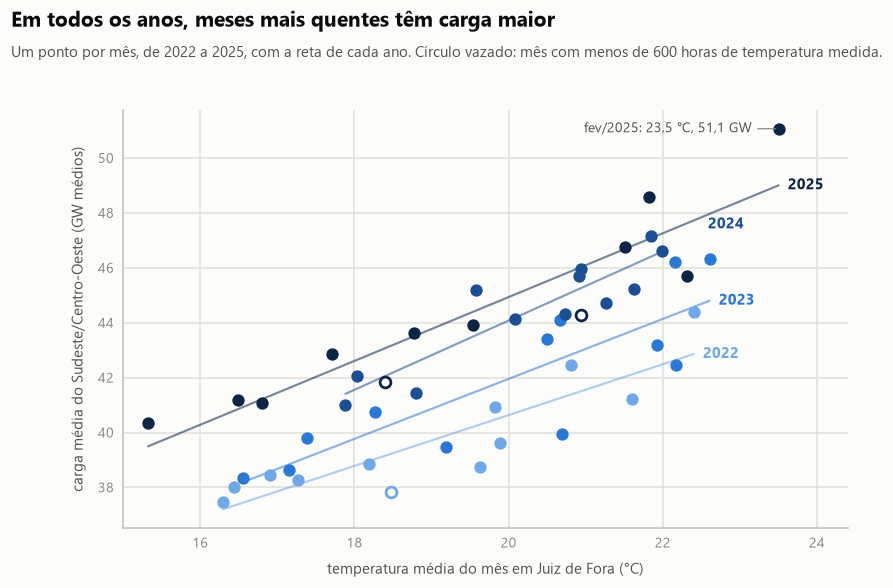

2022 0.93
2023 1.09
2024 1.26
2025 1.16


In [28]:
e.aplica_tema()
cores = {2022: "#6fa8e8", 2023: "#2a78d6", 2024: "#1b4f94", 2025: "#0b2447"}
fig, ax = plt.subplots(figsize=(8.5, 5.4))

for ano, d in mensal.groupby("ano"):
    x, y = d["temp"], d["carga"] / 1000
    a, b = np.polyfit(x, y, 1)
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, a * xs + b, color=cores[ano], lw=1.4, alpha=0.55, zorder=2)

    cheio = d["horas"] >= 600
    ax.scatter(x[cheio], y[cheio], s=50, color=cores[ano], zorder=3)
    ax.scatter(x[~cheio], y[~cheio], s=50, facecolor=e.SUPERFICIE,
               edgecolor=cores[ano], linewidth=1.8, zorder=3)

    dx, dy = {2024: (0.6, 1.0)}.get(ano, (0.12, 0))
    ax.text(xs[1] + dx, a * xs[1] + b + dy, str(ano), color=cores[ano],
            fontsize=10, fontweight="bold", va="center")

ax.set_xlim(15, 24.4)
ax.set_xlabel("temperatura média do mês em Juiz de Fora (°C)")
ax.set_ylabel("carga média do Sudeste/Centro-Oeste (GW médios)")
e.formato_br(ax, "x", 0)
e.formato_br(ax, "y", 0)

pico = mensal.loc["2025-02"]
e.anota(ax, f"fev/2025: {e.num(pico['temp'], 1)} °C, {e.num(pico['carga'] / 1000, 1)} GW",
        xy=(pico["temp"], pico["carga"] / 1000),
        xytext=(pico["temp"] - 0.35, pico["carga"] / 1000), ha="right")

e.titulo(fig, "Em todos os anos, meses mais quentes têm carga maior",
         "Um ponto por mês, de 2022 a 2025, com a reta de cada ano. "
         "Círculo vazado: mês com menos de 600 horas de temperatura medida.", topo=1.0)
e.salva(fig, "01_carga_vs_temperatura")
plt.show()

for ano, d in mensal.groupby("ano"):
    print(ano, round(np.polyfit(d["temp"], d["carga"] / 1000, 1)[0], 2))

Em todos os anos, os meses mais quentes têm carga maior, e as retas de cada ano têm inclinação parecida, entre 0,93 e 1,26 GW a mais por grau, com 12 pontos por reta. Para a mesma temperatura, 2022 fica abaixo de 2023 e 2023 abaixo de 2024, então parte do aumento da carga ao longo dos anos não vem do calor. O ponto mais alto é fevereiro de 2025, com 23,5 °C e 51,1 GW.

O gráfico mostra que carga e temperatura variam juntas. Não mostra que o calor causa o consumo: a estação do ano e outros fatores mudam ao mesmo tempo, e a temperatura é a de uma estação em Juiz de Fora, não a do Sudeste inteiro.

O segundo gráfico pergunta como o preço dos combustíveis mudou em Juiz de Fora. É uma série no tempo, então uso linhas, uma por produto, com o número de observações de cada mês embaixo, porque ele varia muito.

In [29]:
precos_jf["mes"] = precos_jf["Data da Coleta"].dt.to_period("M")
meses = pd.period_range(precos_jf["mes"].min(), precos_jf["mes"].max(), freq="M")

preco = precos_jf.groupby(["mes", "Produto"])["Valor de Venda"].mean().unstack().reindex(meses)
obs = precos_jf.groupby("mes").size().reindex(meses)

print(preco.shape)
print(obs[obs < 100])
print(preco.isna().all(axis=1).sum(), list(meses[preco.isna().all(axis=1)]))
print(preco.min().round(2).to_dict(), preco.max().round(2).to_dict())
print(preco.loc[["2023-01", "2026-09"]].round(2))
print(obs[obs >= 100].agg(["min", "max"]), obs.median())

(45, 3)
2024-12    15.0
2025-01    24.0
2025-02    30.0
2025-03    62.0
Freq: M, dtype: float64
1 [Period('2026-04', 'M')]
{'ETANOL': 3.89, 'GASOLINA': 5.09, 'GASOLINA ADITIVADA': 5.21} {'ETANOL': 4.98, 'GASOLINA': 6.66, 'GASOLINA ADITIVADA': 6.87}
Produto  ETANOL  GASOLINA  GASOLINA ADITIVADA
2023-01    4.16      5.12                5.28
2026-09    4.47      6.61                6.84
min    134.0
max    226.0
dtype: float64 178.0


Os 45 meses de janeiro de 2023 a setembro de 2026 incluem um vazio, abril de 2026. A gasolina comum vai de R$ 5,12 em janeiro de 2023 a R$ 6,61 em setembro de 2026, e o etanol oscila entre R$ 3,89 e R$ 4,98 na média mensal. Quatro meses têm poucas observações, de dezembro de 2024 a março de 2025 (15, 24, 30 e 62), contra uma mediana mensal de 178.

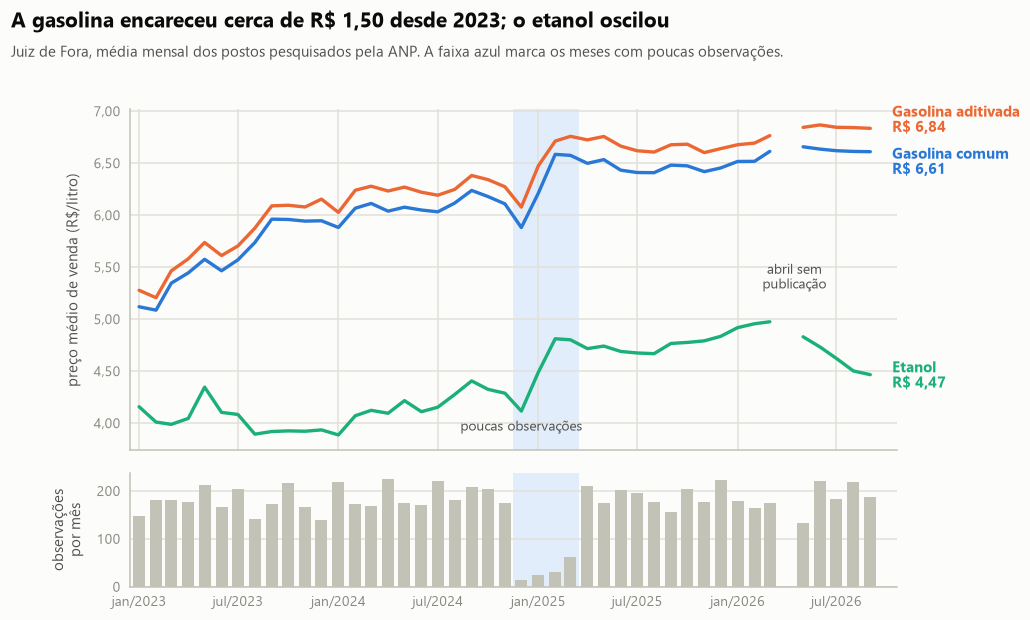

In [30]:
x = meses.to_timestamp()
fig, (ax, ab) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                             gridspec_kw={"height_ratios": [3, 1], "hspace": 0.1})

faixa = (pd.Timestamp("2024-11-16"), pd.Timestamp("2025-03-16"))
for eixo in (ax, ab):
    eixo.axvspan(*faixa, color=e.AZUL_FAIXA, alpha=0.55, lw=0, zorder=0)

series = [("GASOLINA ADITIVADA", "Gasolina aditivada", e.LARANJA),
          ("GASOLINA", "Gasolina comum", e.AZUL),
          ("ETANOL", "Etanol", e.VERDE_AGUA)]
desloc = {"GASOLINA ADITIVADA": 0.09, "GASOLINA": -0.09}

for produto, nome, cor in series:
    ax.plot(x, preco[produto].values, color=cor, lw=2.2, zorder=3)
    ultimo = preco[produto].dropna().iloc[-1]
    ax.text(x[-1] + pd.Timedelta(days=40), ultimo + desloc.get(produto, 0),
            f"{nome}\nR$ {e.num(ultimo)}", color=cor, fontsize=9.5,
            fontweight="bold", va="center", linespacing=1.15)

ax.text(pd.Timestamp("2024-12-01"), 3.9, "poucas observações",
        color=e.TINTA_2, fontsize=9, ha="center", va="bottom")
ax.text(pd.Timestamp("2026-04-15"), 5.4, "abril sem\npublicação",
        color=e.TINTA_2, fontsize=9, ha="center", va="center")
ax.set_ylabel("preço médio de venda (R$/litro)")
e.formato_br(ax, "y", 2)
ax.set_xlim(pd.Timestamp("2022-12-15"), pd.Timestamp("2026-10-20"))

ab.bar(x, obs.values, width=22, color=e.CINZA_FORA, zorder=3)
ab.set_ylabel("observações\npor mês")
ab.grid(axis="x", visible=False)
ab.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
abrev = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
ab.xaxis.set_major_formatter(plt.FuncFormatter(
    lambda v, _: f"{abrev[mdates.num2date(v).month - 1]}/{mdates.num2date(v).year}"))

e.titulo(fig, "A gasolina encareceu cerca de R$ 1,50 desde 2023; o etanol oscilou",
         "Juiz de Fora, média mensal dos postos pesquisados pela ANP. "
         "A faixa azul marca os meses com poucas observações.", topo=1.0)
e.salva(fig, "02_preco_combustivel")
plt.show()

O salto de preço do fim de 2024 ao início de 2025 acontece justamente nos meses de poucas observações: a gasolina comum sai de cerca de R$ 5,90 para R$ 6,60. Com 15 a 62 registros, a média do mês depende de quais postos foram pesquisados, e os dados não permitem separar aumento real de efeito da amostra pequena. Depois que a coleta volta ao normal, em abril de 2025, o preço fica perto do novo patamar, o que sugere que o aumento foi real, mas é um indício.

No período todo, a gasolina encareceu cerca de R$ 1,50. O etanol subiu até R$ 4,98 em março de 2026 e depois caiu para R$ 4,47 em setembro, movimento diferente do da gasolina, que ficou perto de R$ 6,60.

## Qualidade das fontes

Para fechar, o que faltou em cada uma.

In [31]:
qualidade = pd.DataFrame({
    "fonte": ["ONS carga diária", "INMET A518 horário", "ANP gasolina e etanol"],
    "registros": [len(carga), len(clima_jf), len(precos_jf)],
    "sem valor": [carga["val_cargaenergiamwmed"].isna().sum(),
                  clima_jf[col_temp].isna().sum(),
                  precos_jf["Valor de Venda"].isna().sum()],
    "primeiro": [carga["din_instante"].min(), clima_jf["momento"].min(), precos_jf["Data da Coleta"].min()],
    "último": [carga["din_instante"].max(), clima_jf["momento"].max(), precos_jf["Data da Coleta"].max()],
})
qualidade["% sem valor"] = (qualidade["sem valor"] / qualidade["registros"] * 100).round(2)
qualidade

,fonte,registros,sem valor,primeiro,último,% sem valor
0,ONS carga diária,39116,12,2000-01-01,2026-10-09 00:00:00,0.03
1,INMET A518 horário,35064,1201,2022-01-01,2025-12-31 23:00:00,3.43
2,ANP gasolina e etanol,7545,0,2023-01-13,2026-09-28 00:00:00,0.00


O ONS tem 12 de 39.116 linhas sem valor (0,03%), todas de 2013 a 2015, fora do período que cruzo com as outras fontes. O INMET tem 1.201 de 35.064 horas sem temperatura (3,43%), concentradas em julho de 2022 e em março a maio de 2025. A ANP não tem preço vazio, mas tem quatro meses de coleta pequena no município e um mês inteiro ausente.

Os três históricos ficam em `data/` (`historico_carga_ons.csv`, `historico_inmet_A518.csv` e `historico_anp_jf.csv`), fora do Git, e servem de base para os projetos seguintes.